# 02. Baselines

Two baselines on both datasets with the official splits and five seeds:

| Baseline | Model | Input |
|---|---|---|
| A | Text-only MLP | BERT vector of the root (news) node |
| B | Random Forest | Graph statistics of the propagation network, no text |

## 1. Setup

In [1]:
# Imports and software versions used for this run.
import sys, time, platform, warnings, random, logging, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import sklearn
import joblib
import torch
import torch.nn as nn
import torch_geometric
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, precision_recall_fscore_support

warnings.filterwarnings("ignore", category=FutureWarning)
# Hide a scikit-learn warning that is repeated many times during permutation importance.
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

versions = {"Python": sys.version.split()[0], "Platform": platform.platform(), "NumPy": np.__version__,
            "Pandas": pd.__version__, "SciPy": scipy.__version__, "scikit-learn": sklearn.__version__,
            "NetworkX": nx.__version__,
            "PyTorch": torch.__version__,
            "PyG": torch_geometric.__version__}
for k, v in versions.items():
    print(f"{k:<14}{v}")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("\nDevice:", DEVICE)


Python        3.13.13
Platform      Windows-11-10.0.26200-SP0
NumPy         2.4.3
Pandas        2.3.3
SciPy         1.17.1
scikit-learn  1.8.0
NetworkX      3.6.1
PyTorch       2.11.0+cpu
PyG           2.8.1

Device: cpu


In [2]:
# Shared settings, paths, data loader and graph statistics (see upfd_common.py).
from upfd_common import *


Working directory: C:\Users\shara\FakeNews-detection-GNN\fake_news_gnn_final_notebooks
Project root     : C:\Users\shara\FakeNews-detection-GNN
UPFD data root   : C:\Users\shara\FakeNews-detection-GNN\data\upfd (found)


## 2. Settings

In [3]:
# Seeds, hyperparameters, output folders and logging.
SEEDS = [42, 43, 44, 45, 46]

MLP_HP = {
    "hidden_dim": 128,
    "dropout": 0.5,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "batch_size": 32,
    "max_epochs": 300,
    "patience": 30,
    "min_delta": 1e-4,
    "standardize": True,
}
RF_FIXED = {"n_estimators": 200}
RF_GRID = {"max_depth": [None, 4, 8], "min_samples_leaf": [1, 3, 5]}

BASE_METRICS_DIR = METRICS_DIR / "baselines"
BASE_FIG_DIR = FIGURES_DIR / "baselines"
BASE_LOG_DIR = LOGS_DIR / "baselines"
BASE_CKPT_DIR = CHECKPOINTS_DIR / "baselines"
for _d in (BASE_METRICS_DIR, BASE_FIG_DIR, BASE_LOG_DIR, BASE_CKPT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

RUN_ID = time.strftime("%Y%m%d_%H%M%S")
LOG_PATH = BASE_LOG_DIR / f"baselines_{RUN_ID}.log"
logger = logging.getLogger("baselines")
logger.setLevel(logging.INFO)
logger.handlers.clear()
_fh = logging.FileHandler(LOG_PATH, mode="a", encoding="utf-8")
_fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
logger.addHandler(_fh)
logger.info("Notebook 02 started. seeds=%s device=%s versions=%s", SEEDS, DEVICE, versions)
print("Log file:", LOG_PATH.relative_to(PROJECT_ROOT))


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


Log file: results\logs\baselines\baselines_20261108_223418.log


## 3. Load data and checks

In [4]:
# Load the data and repeat the essential checks before training.
RAW = {}
for name in DATASETS:
    t0 = time.perf_counter()
    RAW[name] = load_upfd_raw(name)
    r = RAW[name]
    print(f"{DATASET_TITLES[name]:<11} loaded in {time.perf_counter() - t0:5.1f}s | layout={r['layout']:<4} | graphs={r['n_graphs']:,} | "
          f"nodes={r['n_nodes']:,} | features {r['X'].shape}")
    assert len(r["classes_raw"]) == 2, f"{name}: expected 2 classes, got {r['classes_raw']}"
    assert r["X"].shape[1] == EXPECTED_FEATURE_DIM, f"{name}: feature dim {r['X'].shape[1]} != {EXPECTED_FEATURE_DIM}"

    split_df, overlaps, coverage = check_splits(r)
    assert all(v == 0 for v in overlaps.values()), f"{name}: splits overlap {overlaps} -> data leakage!"
    assert split_df["duplicates"].sum() == 0 and split_df["out_of_range"].sum() == 0
    print(f"   splits (train/val/test graphs): {[len(r['splits'][s]) for s in SPLITS]} | overlaps: {overlaps} | coverage: {coverage}")
    summarize_root_check(root_convention_check(r), DATASET_TITLES[name])  # stops if node 0 is not the root

if FAKE_CLASS_INDEX is None:
    print("LABEL SEMANTICS UNVERIFIED: classes are reported as class 0 / class 1. ROC-AUC and the macro-averaged "
          "metrics are unaffected by which class is 'fake'; per-class precision/recall are saved for both classes.")


PolitiFact  loaded in   4.0s | layout=flat | graphs=314 | nodes=41,054 | features (41054, 768)
   splits (train/val/test graphs): [62, 31, 221] | overlaps: {'train & val': 0, 'train & test': 0, 'val & test': 0} | coverage: {'graphs_in_union': 314, 'total_graphs': 314, 'graphs_in_no_split': 0}
GossipCop   loaded in  30.7s | layout=flat | graphs=5,464 | nodes=314,262 | features (314262, 768)
   splits (train/val/test graphs): [1092, 546, 3826] | overlaps: {'train & val': 0, 'train & test': 0, 'val & test': 0} | coverage: {'graphs_in_union': 5464, 'total_graphs': 5464, 'graphs_in_no_split': 0}
LABEL SEMANTICS UNVERIFIED: classes are reported as class 0 / class 1. ROC-AUC and the macro-averaged metrics are unaffected by which class is 'fake'; per-class precision/recall are saved for both classes.


## 4. Evaluation helpers

In [5]:
# Figures are drawn for the first seed only.
SHOW_PLOTS = True


def show_or_close(fig):
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


show_cols = ["dataset", "seed", "split", "n", "accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc"]


# Accuracy, macro metrics, ROC-AUC and per-class metrics.
def compute_metrics(y_true, y_pred, y_score):
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    out = {
        "n": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score) if len(np.unique(y_true)) == 2 else np.nan,
    }
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    for c in (0, 1):
        out[f"precision_class{c}"], out[f"recall_class{c}"], out[f"f1_class{c}"], out[f"support_class{c}"] = p[c], r[c], f[c], int(s[c])
    if FAKE_CLASS_INDEX is not None:
        real = 1 - FAKE_CLASS_INDEX
        out["precision_fake"], out["recall_fake"] = p[FAKE_CLASS_INDEX], r[FAKE_CLASS_INDEX]
        out["precision_real"], out["recall_real"] = p[real], r[real]
    return out


# Add new runs to a CSV, replacing older rows for the same dataset, model, seed and split.
def append_run_metrics(rows, csv_path):
    new = pd.DataFrame(rows)
    if csv_path.is_file():
        old = pd.read_csv(csv_path)
        key = ["dataset", "model", "seed", "split"]
        old = old.merge(new[key].drop_duplicates(), on=key, how="left", indicator=True)
        old = old[old["_merge"] == "left_only"].drop(columns="_merge")
        new = pd.concat([old, new], ignore_index=True)
    save_dataframe(new, csv_path)
    return new

## 5. Baseline A: Text-only MLP

Input is the root-node BERT vector (768 numbers). Model: `Linear(768, 128) → ReLU → Dropout(0.5) → Linear(128, 2)`, trained with Adam and early stopping on validation loss. Features are standardised using training data only. Plots are shown for the first seed only.

In [6]:
# The text baseline uses only the BERT vector of the root (news) node.
def build_text_dataset(raw):
    data = {}
    for s in SPLITS:
        idx = raw["splits"][s]
        data[s] = {"idx": idx, "X": root_features(raw, idx).astype(np.float32), "y": raw["y"][idx]}
        assert data[s]["X"].shape == (len(idx), EXPECTED_FEATURE_DIM)

    assert not (set(data["train"]["idx"]) & set(data["test"]["idx"])) and not (set(data["train"]["idx"]) & set(data["val"]["idx"]))
    return data


TEXT_DATA = {name: build_text_dataset(RAW[name]) for name in DATASETS}
rows = []
for name in DATASETS:
    for s in SPLITS:
        d = TEXT_DATA[name][s]
        cnt = np.bincount(d["y"], minlength=2)
        rows.append({"dataset": DATASET_TITLES[name], "split": s, "X shape": d["X"].shape, "y shape": d["y"].shape,
                     "class 0": int(cnt[0]), "class 1": int(cnt[1]), "class-1 share": round(cnt[1] / cnt.sum(), 3)})
display(pd.DataFrame(rows))

,dataset,split,X shape,y shape,class 0,class 1,class-1 share
0,PolitiFact,train,"(62, 768)","(62,)",36,26,0.419
1,PolitiFact,val,"(31, 768)","(31,)",13,18,0.581
2,PolitiFact,test,"(221, 768)","(221,)",108,113,0.511
3,GossipCop,train,"(1092, 768)","(1092,)",557,535,0.490
4,GossipCop,val,"(546, 768)","(546,)",265,281,0.515
5,GossipCop,test,"(3826, 768)","(3826,)",1910,1916,0.501


In [7]:
# One hidden layer classifier.
def build_mlp(in_dim, hidden_dim, dropout, n_classes=2):
    return nn.Sequential(nn.Linear(in_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden_dim, n_classes))


# Return predicted classes and the probability of class 1.
def predict_mlp(model, X, device):
    model.eval()
    with torch.no_grad():
        logits = model(torch.as_tensor(X, dtype=torch.float32, device=device))
        proba = torch.softmax(logits, dim=1).cpu().numpy()
    return proba.argmax(axis=1), proba[:, 1]


# Train with early stopping on validation loss and restore the best epoch.
def train_mlp(Xtr, ytr, Xva, yva, seed, hp, device):
    set_seed(seed)
    model = build_mlp(Xtr.shape[1], hp["hidden_dim"], hp["dropout"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])
    loss_fn = nn.CrossEntropyLoss()
    Xtr_t = torch.as_tensor(Xtr, dtype=torch.float32, device=device)
    ytr_t = torch.as_tensor(ytr, dtype=torch.long, device=device)
    Xva_t = torch.as_tensor(Xva, dtype=torch.float32, device=device)
    yva_t = torch.as_tensor(yva, dtype=torch.long, device=device)
    gen = torch.Generator().manual_seed(seed)

    n, history = len(Xtr_t), []
    best_val, best_epoch, best_state, bad_epochs = np.inf, 0, None, 0
    for epoch in range(1, hp["max_epochs"] + 1):
        model.train()
        order = torch.randperm(n, generator=gen).to(device)
        for start in range(0, n, hp["batch_size"]):
            batch = order[start:start + hp["batch_size"]]
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(Xtr_t[batch]), ytr_t[batch])
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            tr_logits, va_logits = model(Xtr_t), model(Xva_t)
            tr_loss, va_loss = loss_fn(tr_logits, ytr_t).item(), loss_fn(va_logits, yva_t).item()
            tr_pred, va_pred = tr_logits.argmax(1).cpu().numpy(), va_logits.argmax(1).cpu().numpy()
        history.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss,
                        "train_acc": accuracy_score(ytr, tr_pred), "val_acc": accuracy_score(yva, va_pred),
                        "val_f1_macro": f1_score(yva, va_pred, average="macro", zero_division=0)})
        if va_loss < best_val - hp["min_delta"]:
            best_val, best_epoch, bad_epochs = va_loss, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= hp["patience"]:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), {"best_epoch": best_epoch, "best_val_loss": best_val, "epochs_run": len(history)}


def plot_history(hist, best_epoch, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist.epoch, hist.train_loss, label="training loss")
    axes[0].plot(hist.epoch, hist.val_loss, label="validation loss")
    axes[0].axvline(best_epoch, color="grey", ls="--", lw=1, label=f"selected epoch {best_epoch}")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy"); axes[0].set_title("loss curves"); axes[0].legend()
    axes[1].plot(hist.epoch, hist.train_acc, label="training accuracy")
    axes[1].plot(hist.epoch, hist.val_acc, label="validation accuracy")
    axes[1].plot(hist.epoch, hist.val_f1_macro, label="validation macro-F1")
    axes[1].axvline(best_epoch, color="grey", ls="--", lw=1)
    axes[1].set_ylim(0, 1.02); axes[1].set_xlabel("epoch"); axes[1].set_title("performance history"); axes[1].legend()
    fig.suptitle(title); plt.tight_layout(); save_figure(fig, path); show_or_close(fig)


Text-only MLP | PolitiFact | seed 42


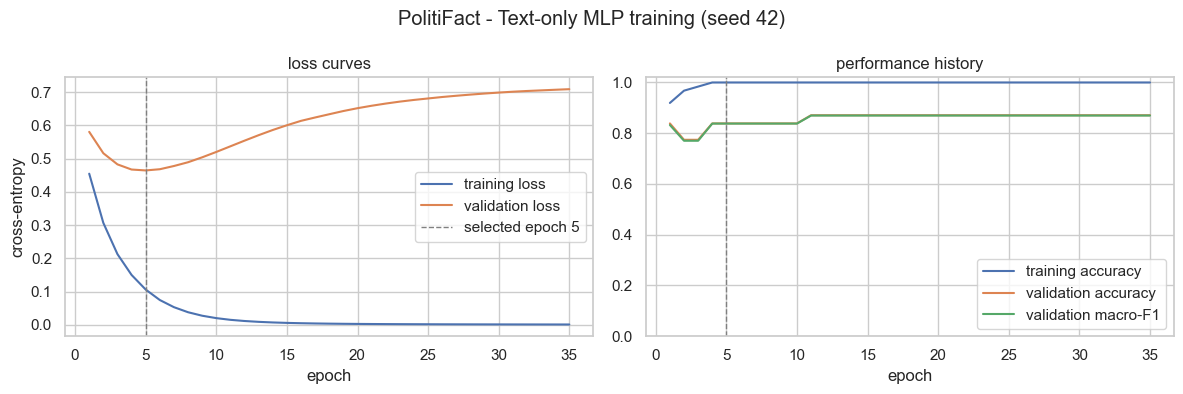


Text-only MLP | GossipCop | seed 42


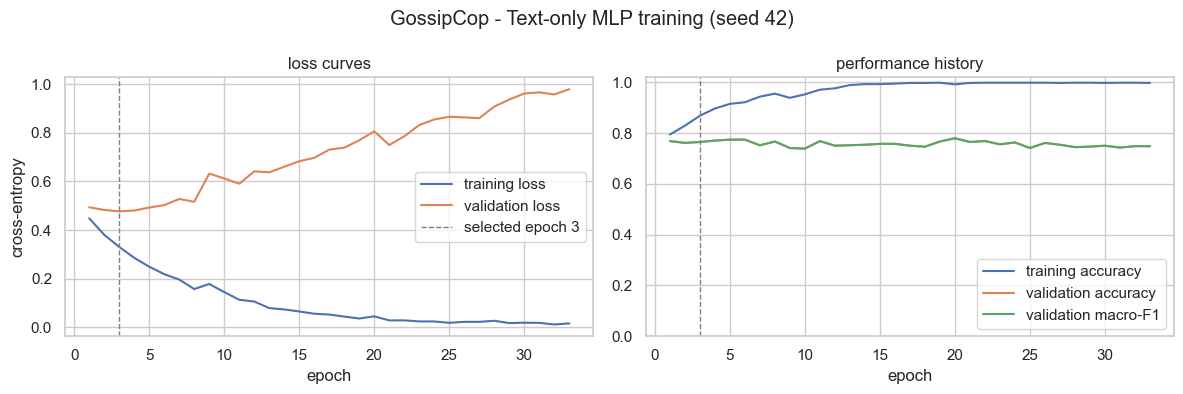


Text-only MLP | PolitiFact | seed 43

Text-only MLP | GossipCop | seed 43

Text-only MLP | PolitiFact | seed 44

Text-only MLP | GossipCop | seed 44

Text-only MLP | PolitiFact | seed 45

Text-only MLP | GossipCop | seed 45

Text-only MLP | PolitiFact | seed 46

Text-only MLP | GossipCop | seed 46


,dataset,seed,split,n,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
0,PolitiFact,42,val,31,0.8387,0.8417,0.8504,0.8380,0.8675
1,PolitiFact,42,test,221,0.8009,0.8126,0.8031,0.7997,0.8533
2,GossipCop,42,val,546,0.7656,0.7673,0.7667,0.7655,0.8508
3,GossipCop,42,test,3826,0.7389,0.7436,0.7390,0.7377,0.8108
4,PolitiFact,43,val,31,0.8710,0.8688,0.8782,0.8697,0.8803
5,PolitiFact,43,test,221,0.7964,0.8091,0.7986,0.7950,0.8627
6,GossipCop,43,val,546,0.7674,0.7687,0.7683,0.7674,0.8437
7,GossipCop,43,test,3826,0.7397,0.7440,0.7398,0.7386,0.8078
8,PolitiFact,44,val,31,0.8387,0.8417,0.8504,0.8380,0.8718
9,PolitiFact,44,test,221,0.8281,0.8344,0.8296,0.8276,0.8673


In [8]:
# Train and evaluate the MLP for one dataset and seed, then save the results.
def run_text_mlp(name, seed, hp=MLP_HP, device=DEVICE):
    title = DATASET_TITLES[name]
    d = TEXT_DATA[name]
    t0 = time.perf_counter()

    # Standardise with training data only.
    Xtr, Xva, Xte = d["train"]["X"], d["val"]["X"], d["test"]["X"]
    scaler_mean, scaler_scale = None, None
    if hp["standardize"]:
        scaler = StandardScaler().fit(Xtr)
        scaler_mean, scaler_scale = scaler.mean_.astype(np.float32), scaler.scale_.astype(np.float32)
        Xtr, Xva, Xte = scaler.transform(Xtr), scaler.transform(Xva), scaler.transform(Xte)

    model, hist, info = train_mlp(Xtr, d["train"]["y"], Xva, d["val"]["y"], seed, hp, device)
    train_time = time.perf_counter() - t0

    rows = []
    preds = {}
    for split, X in (("val", Xva), ("test", Xte)):
        y_true = d[split]["y"]
        y_pred, y_score = predict_mlp(model, X, device)
        preds[split] = (y_true, y_pred, y_score)
        rows.append({"dataset": title, "dataset_key": name, "model": "Text-only MLP", "feature_type": f"root-node {FEATURE} (768-d)",
                     "seed": seed, "split": split, **compute_metrics(y_true, y_pred, y_score)})
    test_row = [r for r in rows if r["split"] == "test"][0]

    tag = f"text_mlp_{name}_seed{seed}"
    hist.to_csv(BASE_LOG_DIR / f"{tag}_history.csv", index=False)
    ckpt = BASE_CKPT_DIR / "text_mlp" / f"{tag}.pt"
    ckpt.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"state_dict": model.state_dict(), "hyperparameters": hp, "seed": seed, "dataset": name,
                "scaler_mean": None if scaler_mean is None else torch.as_tensor(scaler_mean),
                "scaler_scale": None if scaler_scale is None else torch.as_tensor(scaler_scale),
                "input": "root-node BERT vector (768)"}, ckpt)

    # Learning curves are drawn and saved for the first seed only.
    if SHOW_PLOTS:
        plot_history(hist, info["best_epoch"], f"{title} - Text-only MLP training (seed {seed})", BASE_FIG_DIR / "text_mlp" / f"{tag}_learning_curves.png")

    meta = {"dataset": title, "model": "Text-only MLP", "feature_type": f"root-node {FEATURE} (768-d), graph.x[0] only",
            "uses_text": True, "uses_graph_structure": False, "seed": seed, "hyperparameters": hp,
            "train_graphs": len(d["train"]["y"]), "val_graphs": len(d["val"]["y"]), "test_graphs": len(d["test"]["y"]),
            "device": str(device), "training_time_seconds": round(train_time, 2), **info,
            "selection_criterion": "lowest validation cross-entropy (early stopping)",
            "label_semantics": "unverified (class 0/1)" if FAKE_CLASS_INDEX is None else f"class {FAKE_CLASS_INDEX} = fake",
            "metrics_test": {k: test_row[k] for k in ("accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc")},
            "versions": versions, "run_id": RUN_ID}
    save_json(meta, BASE_METRICS_DIR / f"{tag}_metadata.json")
    logger.info("MLP %s seed=%d best_epoch=%d epochs=%d time=%.1fs test=%s", name, seed, info["best_epoch"], info["epochs_run"], train_time, meta["metrics_test"])
    return rows


MLP_ROWS = []
for seed in SEEDS:
    SHOW_PLOTS = seed == SEEDS[0]
    for name in DATASETS:
        print(f"\nText-only MLP | {DATASET_TITLES[name]} | seed {seed}")
        MLP_ROWS += run_text_mlp(name, seed)
MLP_METRICS = append_run_metrics(MLP_ROWS, BASE_METRICS_DIR / "baseline_text_mlp_metrics.csv")
display(pd.DataFrame(MLP_ROWS)[show_cols].round(4))

## 6. Baseline B: Propagation-only Random Forest

Input is a set of graph statistics (nodes, depth, degree and leaf measures). Statistics that are exact functions of the node count in the training graphs are dropped. `max_depth` and `min_samples_leaf` are chosen on validation macro-F1.

In [9]:
# Compute the statistics and drop those fully determined by node count.
ALL_STAT_FEATURES = ["num_nodes", "num_edges", "max_depth", "avg_depth", "root_degree",
                     "max_degree", "avg_degree", "degree_std", "leaf_proportion"]

STATS = {}
for name in DATASETS:
    STATS[name] = compute_all_graph_statistics(RAW[name], desc=f"{DATASET_TITLES[name]} structural statistics")
    p = BASE_METRICS_DIR / f"propagation_features_{name}.csv"
    save_dataframe(STATS[name][["graph_idx", "split", "label", "label_raw"] + ALL_STAT_FEATURES + ["is_connected", "is_tree"]], p)
    print(f"{DATASET_TITLES[name]:<11}: {len(STATS[name]):,} graphs -> {p.relative_to(PROJECT_ROOT)}")


def select_rf_features(train_stats):
    dropped = {}
    if (train_stats["num_edges"] == train_stats["num_nodes"] - 1).all():
        dropped["num_edges"] = "equals num_nodes - 1 in every training graph"
    if np.allclose(train_stats["avg_degree"], 2 * (train_stats["num_nodes"] - 1) / train_stats["num_nodes"]):
        dropped["avg_degree"] = "equals 2(n-1)/n in every training graph"
    return [f for f in ALL_STAT_FEATURES if f not in dropped], dropped


RF_FEATURES, RF_DROPPED = {}, {}
for name in DATASETS:
    train_stats = STATS[name][STATS[name]["split"] == "train"]
    RF_FEATURES[name], RF_DROPPED[name] = select_rf_features(train_stats)
    print(f"{DATASET_TITLES[name]:<11}: using {len(RF_FEATURES[name])} features {RF_FEATURES[name]}")
    for f, why in RF_DROPPED[name].items():
        print(f"{'':<13}dropped '{f}' ({why})")
    assert not any(c.startswith("bert") or c == "x" for c in RF_FEATURES[name])

PolitiFact structural statistics:   0%|          | 0/314 [00:00<?, ?it/s]

PolitiFact : 314 graphs -> results\metrics\baselines\propagation_features_politifact.csv


GossipCop structural statistics:   0%|          | 0/5464 [00:00<?, ?it/s]

GossipCop  : 5,464 graphs -> results\metrics\baselines\propagation_features_gossipcop.csv
PolitiFact : using 7 features ['num_nodes', 'max_depth', 'avg_depth', 'root_degree', 'max_degree', 'degree_std', 'leaf_proportion']
             dropped 'num_edges' (equals num_nodes - 1 in every training graph)
             dropped 'avg_degree' (equals 2(n-1)/n in every training graph)
GossipCop  : using 7 features ['num_nodes', 'max_depth', 'avg_depth', 'root_degree', 'max_degree', 'degree_std', 'leaf_proportion']
             dropped 'num_edges' (equals num_nodes - 1 in every training graph)
             dropped 'avg_degree' (equals 2(n-1)/n in every training graph)


In [10]:
# Build the feature matrix for each split.
def build_structure_dataset(name):
    stats = STATS[name].set_index("graph_idx")
    data = {}
    for s in SPLITS:
        idx = RAW[name]["splits"][s]
        data[s] = {"idx": idx, "X": stats.loc[idx, RF_FEATURES[name]].to_numpy(dtype=np.float64), "y": RAW[name]["y"][idx]}
        assert (stats.loc[idx, "label"].to_numpy() == data[s]["y"]).all()
        assert not np.isnan(data[s]["X"]).any()
    return data


STRUCT_DATA = {name: build_structure_dataset(name) for name in DATASETS}
rows = []
for name in DATASETS:
    for s in SPLITS:
        d = STRUCT_DATA[name][s]
        cnt = np.bincount(d["y"], minlength=2)
        rows.append({"dataset": DATASET_TITLES[name], "split": s, "X shape": d["X"].shape, "class 0": int(cnt[0]), "class 1": int(cnt[1])})
display(pd.DataFrame(rows))

,dataset,split,X shape,class 0,class 1
0,PolitiFact,train,"(62, 7)",36,26
1,PolitiFact,val,"(31, 7)",13,18
2,PolitiFact,test,"(221, 7)",108,113
3,GossipCop,train,"(1092, 7)",557,535
4,GossipCop,val,"(546, 7)",265,281
5,GossipCop,test,"(3826, 7)",1910,1916



Propagation-only RF | PolitiFact | seed 42


,max_depth,min_samples_leaf,val_f1_macro,val_roc_auc,val_accuracy
0,NaN,1,0.4493,0.5385,0.4516
1,NaN,3,0.4493,0.5641,0.4516
2,NaN,5,0.5241,0.5897,0.5484
3,4.0,1,0.4561,0.5470,0.4839
4,4.0,3,0.3659,0.5556,0.4194
5,4.0,5,0.4816,0.5726,0.5161
6,8.0,1,0.4833,0.5342,0.4839
7,8.0,3,0.4493,0.5598,0.4516
8,8.0,5,0.5241,0.5897,0.5484


selected on validation: max_depth=None, min_samples_leaf=5, class_weight=None


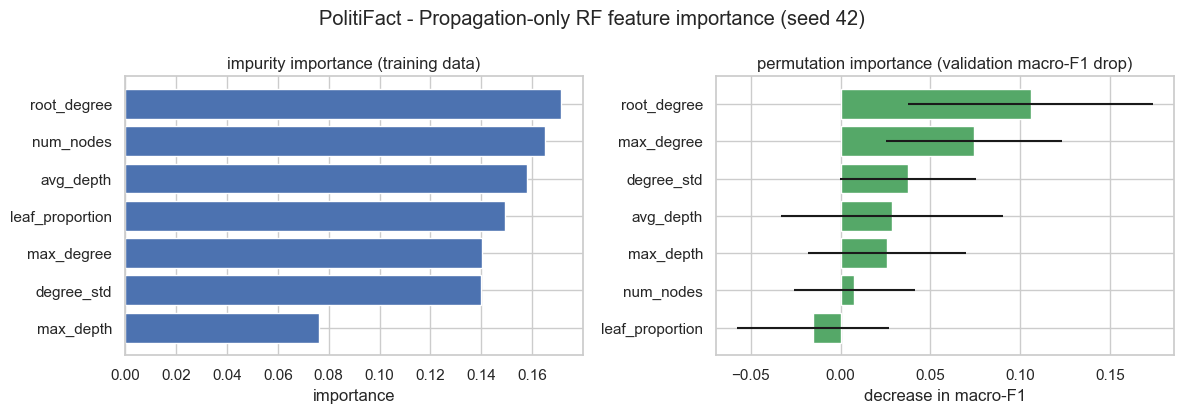

,feature,impurity_importance,permutation_importance_val_mean,permutation_importance_val_std
3,root_degree,0.1714,0.1058,0.0681
0,num_nodes,0.1651,0.0076,0.0338
2,avg_depth,0.1578,0.0287,0.0619
6,leaf_proportion,0.1495,-0.0155,0.0422
4,max_degree,0.1402,0.0741,0.0491
5,degree_std,0.1397,0.0375,0.0380
1,max_depth,0.0763,0.0257,0.0439



Propagation-only RF | GossipCop | seed 42


,max_depth,min_samples_leaf,val_f1_macro,val_roc_auc,val_accuracy
0,NaN,1,0.8075,0.8884,0.8077
1,NaN,3,0.8168,0.9004,0.8168
2,NaN,5,0.8241,0.9012,0.8242
3,4.0,1,0.8351,0.9039,0.8352
4,4.0,3,0.8333,0.9055,0.8333
5,4.0,5,0.8315,0.9053,0.8315
6,8.0,1,0.8241,0.9001,0.8242
7,8.0,3,0.8241,0.9035,0.8242
8,8.0,5,0.8260,0.9029,0.8260


selected on validation: max_depth=4, min_samples_leaf=1, class_weight=None


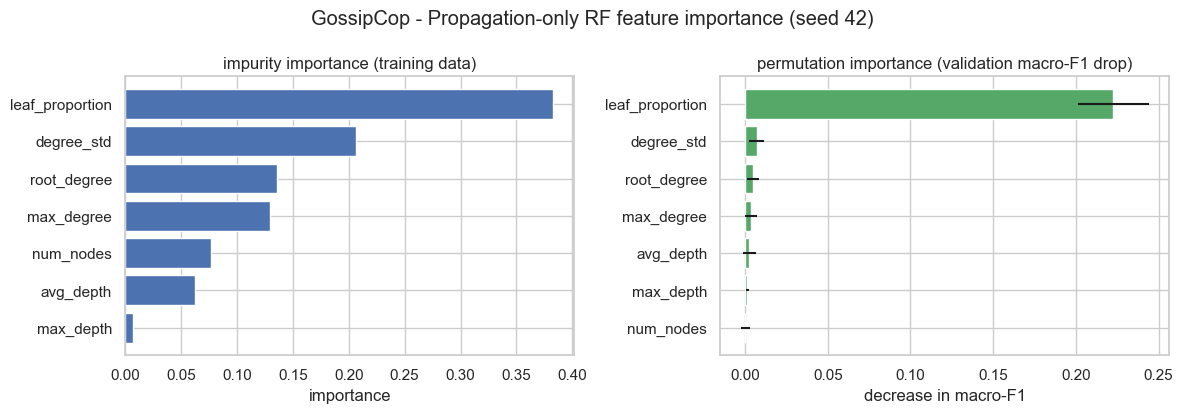

,feature,impurity_importance,permutation_importance_val_mean,permutation_importance_val_std
6,leaf_proportion,0.3824,0.2227,0.0215
5,degree_std,0.2067,0.0069,0.0044
3,root_degree,0.1354,0.0048,0.0038
4,max_degree,0.1296,0.0036,0.0037
0,num_nodes,0.0766,0.0002,0.0028
2,avg_depth,0.0620,0.0025,0.0039
1,max_depth,0.0072,0.0014,0.0008



Propagation-only RF | PolitiFact | seed 43
selected on validation: max_depth=None, min_samples_leaf=1, class_weight=None

Propagation-only RF | GossipCop | seed 43
selected on validation: max_depth=4, min_samples_leaf=1, class_weight=None

Propagation-only RF | PolitiFact | seed 44
selected on validation: max_depth=None, min_samples_leaf=3, class_weight=None

Propagation-only RF | GossipCop | seed 44
selected on validation: max_depth=4, min_samples_leaf=3, class_weight=None

Propagation-only RF | PolitiFact | seed 45
selected on validation: max_depth=None, min_samples_leaf=1, class_weight=None

Propagation-only RF | GossipCop | seed 45
selected on validation: max_depth=4, min_samples_leaf=1, class_weight=None

Propagation-only RF | PolitiFact | seed 46
selected on validation: max_depth=None, min_samples_leaf=5, class_weight=None

Propagation-only RF | GossipCop | seed 46
selected on validation: max_depth=4, min_samples_leaf=1, class_weight=None


,dataset,seed,split,n,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
0,PolitiFact,42,val,31,0.5484,0.6567,0.6004,0.5241,0.5897
1,PolitiFact,42,test,221,0.5294,0.5579,0.5363,0.4848,0.5537
2,GossipCop,42,val,546,0.8352,0.8353,0.8356,0.8351,0.9039
3,GossipCop,42,test,3826,0.8160,0.8167,0.8160,0.8159,0.8878
4,PolitiFact,43,val,31,0.5161,0.5432,0.5406,0.5141,0.5641
5,PolitiFact,43,test,221,0.5249,0.5429,0.5309,0.4923,0.5648
6,GossipCop,43,val,546,0.8352,0.8355,0.8357,0.8352,0.9044
7,GossipCop,43,test,3826,0.8131,0.8141,0.8132,0.8130,0.8878
8,PolitiFact,44,val,31,0.5484,0.5881,0.5791,0.5441,0.5641
9,PolitiFact,44,test,221,0.5204,0.5401,0.5269,0.4808,0.5690


In [11]:
# Tune, train and evaluate the Random Forest for one dataset and seed.
def run_propagation_rf(name, seed):
    title, d, feats = DATASET_TITLES[name], STRUCT_DATA[name], RF_FEATURES[name]
    t0 = time.perf_counter()
    cnt = np.bincount(d["train"]["y"], minlength=2)
    class_weight = "balanced" if cnt.min() / cnt.sum() < 0.40 else None

    # Try every grid setting and keep the best one by validation macro-F1.
    candidates = []
    for max_depth, min_leaf in itertools.product(RF_GRID["max_depth"], RF_GRID["min_samples_leaf"]):
        clf = RandomForestClassifier(**RF_FIXED, max_depth=max_depth, min_samples_leaf=min_leaf,
                                     class_weight=class_weight, random_state=seed, n_jobs=-1)
        clf.fit(d["train"]["X"], d["train"]["y"])
        proba = clf.predict_proba(d["val"]["X"])[:, list(clf.classes_).index(1)]
        m = compute_metrics(d["val"]["y"], clf.predict(d["val"]["X"]), proba)
        candidates.append({"max_depth": max_depth, "min_samples_leaf": min_leaf, "val_f1_macro": m["f1_macro"],
                           "val_roc_auc": m["roc_auc"], "val_accuracy": m["accuracy"], "model": clf})
    key = lambda c: (c["val_f1_macro"], -1 if np.isnan(c["val_roc_auc"]) else c["val_roc_auc"])
    best = max(candidates, key=key)
    clf = best["model"]
    train_time = time.perf_counter() - t0
    grid_df = pd.DataFrame([{k: v for k, v in c.items() if k != "model"} for c in candidates])
    if SHOW_PLOTS:
        display(grid_df.round(4))
    print(f"selected on validation: max_depth={best['max_depth']}, min_samples_leaf={best['min_samples_leaf']}, class_weight={class_weight}")

    rows, preds = [], {}
    pos_col = list(clf.classes_).index(1)
    for split in ("val", "test"):
        y_true = d[split]["y"]
        proba = clf.predict_proba(d[split]["X"])[:, pos_col]
        y_pred = clf.predict(d[split]["X"])
        preds[split] = (y_true, y_pred, proba)
        rows.append({"dataset": title, "dataset_key": name, "model": "Propagation-only RF", "feature_type": "graph structure statistics",
                     "seed": seed, "split": split, **compute_metrics(y_true, y_pred, proba)})
    test_row = [r for r in rows if r["split"] == "test"][0]

    tag = f"propagation_rf_{name}_seed{seed}"
    ckpt = BASE_CKPT_DIR / "propagation_rf" / f"{tag}.joblib"
    ckpt.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump({"model": clf, "features": feats, "seed": seed, "dataset": name}, ckpt, compress=3)
    save_dataframe(grid_df, BASE_METRICS_DIR / f"{tag}_validation_grid.csv")

    # Feature importance is computed and shown for the first seed only.
    if SHOW_PLOTS:
        perm = permutation_importance(clf, d["val"]["X"], d["val"]["y"], scoring="f1_macro", n_repeats=20, random_state=seed, n_jobs=1)
        imp = pd.DataFrame({"feature": feats, "impurity_importance": clf.feature_importances_,
                            "permutation_importance_val_mean": perm.importances_mean, "permutation_importance_val_std": perm.importances_std})
        save_dataframe(imp, BASE_METRICS_DIR / f"{tag}_feature_importance.csv")
        order = imp.sort_values("impurity_importance")
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
        axes[0].barh(order["feature"], order["impurity_importance"], color="#4C72B0")
        axes[0].set_title("impurity importance (training data)"); axes[0].set_xlabel("importance")
        o2 = imp.sort_values("permutation_importance_val_mean")
        axes[1].barh(o2["feature"], o2["permutation_importance_val_mean"], xerr=o2["permutation_importance_val_std"], color="#55A868")
        axes[1].set_title("permutation importance (validation macro-F1 drop)"); axes[1].set_xlabel("decrease in macro-F1")
        fig.suptitle(f"{title} - Propagation-only RF feature importance (seed {seed})"); plt.tight_layout()
        save_figure(fig, BASE_FIG_DIR / "propagation_rf" / f"{tag}_feature_importance.png"); show_or_close(fig)
        display(imp.sort_values("impurity_importance", ascending=False).round(4))

    meta = {"dataset": title, "model": "Propagation-only RF", "feature_type": "graph structure statistics (no text)",
            "uses_text": False, "uses_graph_structure": True, "features_used": feats, "features_dropped_as_redundant": RF_DROPPED[name],
            "seed": seed, "fixed_hyperparameters": RF_FIXED, "tuning_grid": RF_GRID,
            "selected_hyperparameters": {"max_depth": best["max_depth"], "min_samples_leaf": best["min_samples_leaf"], "class_weight": class_weight},
            "selection_criterion": "validation macro-F1 (tie-break: validation ROC-AUC)",
            "train_graphs": len(d["train"]["y"]), "val_graphs": len(d["val"]["y"]), "test_graphs": len(d["test"]["y"]),
            "device": "cpu (scikit-learn)", "training_time_seconds": round(train_time, 2),
            "label_semantics": "unverified (class 0/1)" if FAKE_CLASS_INDEX is None else f"class {FAKE_CLASS_INDEX} = fake",
            "metrics_test": {k: test_row[k] for k in ("accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc")},
            "versions": versions, "run_id": RUN_ID}
    save_json(meta, BASE_METRICS_DIR / f"{tag}_metadata.json")
    logger.info("RF %s seed=%d selected=%s time=%.1fs test=%s", name, seed, meta["selected_hyperparameters"], train_time, meta["metrics_test"])
    return rows


RF_ROWS = []
for seed in SEEDS:
    SHOW_PLOTS = seed == SEEDS[0]
    for name in DATASETS:
        print(f"\nPropagation-only RF | {DATASET_TITLES[name]} | seed {seed}")
        RF_ROWS += run_propagation_rf(name, seed)
RF_METRICS = append_run_metrics(RF_ROWS, BASE_METRICS_DIR / "baseline_propagation_rf_metrics.csv")
display(pd.DataFrame(RF_ROWS)[show_cols].round(4))

## 7. Comparison (test split, mean ± std over seeds)

In [12]:
# Approximate 95% confidence interval for accuracy, treating the mean over seeds as one run.
def wilson_interval(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half


# Combine both baselines into one table of means over the five seeds.
parts = []
for fname in ("baseline_text_mlp_metrics.csv", "baseline_propagation_rf_metrics.csv"):
    p = BASE_METRICS_DIR / fname
    if p.is_file():
        parts.append(pd.read_csv(p))
    else:
        print(f"WARNING: {fname} not found - that baseline has not been run (or failed); it is missing from the comparison.")
if not parts:
    raise RuntimeError("No baseline metrics found. Run the baseline sections first.")
ALL_METRICS = pd.concat(parts, ignore_index=True)
TEST = ALL_METRICS[ALL_METRICS["split"] == "test"]

metric_cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc"]
agg = TEST.groupby(["dataset", "model"], sort=False)[metric_cols].mean().reset_index()
stds = TEST.groupby(["dataset", "model"], sort=False)[metric_cols].std().reset_index()
n_seeds = TEST.groupby(["dataset", "model"], sort=False)["seed"].nunique().reset_index(name="n_seeds")
n_test = TEST.groupby(["dataset", "model"], sort=False)["n"].first().reset_index()
agg = agg.merge(n_seeds).merge(n_test)
lo_hi = [wilson_interval(round(a * n), n) for a, n in zip(agg["accuracy"], agg["n"])]
agg["accuracy_ci95_low"], agg["accuracy_ci95_high"] = [x[0] for x in lo_hi], [x[1] for x in lo_hi]

COMPARISON = agg.rename(columns={"accuracy": "Accuracy", "precision_macro": "Precision (macro)", "recall_macro": "Recall (macro)",
                                 "f1_macro": "Macro F1", "roc_auc": "ROC-AUC", "dataset": "Dataset", "model": "Model",
                                 "n": "test graphs", "n_seeds": "seeds"})
order_models = {"Text-only MLP": 0, "Propagation-only RF": 1}
order_ds = {DATASET_TITLES[n]: i for i, n in enumerate(DATASETS)}
COMPARISON = COMPARISON.sort_values(by=["Dataset", "Model"], key=lambda s: s.map({**order_models, **order_ds})).reset_index(drop=True)
save_dataframe(COMPARISON, BASE_METRICS_DIR / "baseline_comparison.csv")
display(COMPARISON.round(4))

if (TEST["seed"].nunique() > 1):
    save_dataframe(stds.rename(columns=lambda c: f"{c}_std" if c in metric_cols else c), BASE_METRICS_DIR / "baseline_comparison_std_over_seeds.csv")

def mean_std(col):
    g = TEST.groupby(["dataset", "model"], sort=False)[col].agg(["mean", "std"])
    return g.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}" if not np.isnan(r["std"]) else f"{r['mean']:.3f}", axis=1)


SUMMARY_TABLE = pd.DataFrame({"Accuracy": mean_std("accuracy"), "Macro F1": mean_std("f1_macro"), "ROC-AUC": mean_std("roc_auc")}).reset_index()
SUMMARY_TABLE = SUMMARY_TABLE.rename(columns={"dataset": "Dataset", "model": "Model"})
save_dataframe(SUMMARY_TABLE, BASE_METRICS_DIR / "baseline_summary_mean_std.csv")
display(SUMMARY_TABLE)

print("\nMajority-class accuracy on each test split (floor for comparison):")
for name in DATASETS:
    yt = RAW[name]["y"][RAW[name]["splits"]["test"]]
    print(f"  {DATASET_TITLES[name]:<11}: {np.bincount(yt).max() / len(yt):.3f}  ({len(yt)} test graphs; one graph = {100 / len(yt):.2f} accuracy points)")

,Dataset,Model,Accuracy,Precision (macro),Recall (macro),Macro F1,ROC-AUC,seeds,test graphs,accuracy_ci95_low,accuracy_ci95_high
0,PolitiFact,Text-only MLP,0.8127,0.8220,0.8146,0.8118,0.8628,5,221,0.7580,0.8602
1,PolitiFact,Propagation-only RF,0.5195,0.5369,0.5255,0.4856,0.5590,5,221,0.4547,0.5853
2,GossipCop,Text-only MLP,0.7404,0.7454,0.7405,0.7391,0.8106,5,3826,0.7263,0.7541
3,GossipCop,Propagation-only RF,0.8152,0.8160,0.8152,0.8151,0.8881,5,3826,0.8026,0.8272


,Dataset,Model,Accuracy,Macro F1,ROC-AUC
0,PolitiFact,Text-only MLP,0.813 ± 0.017,0.812 ± 0.017,0.863 ± 0.006
1,GossipCop,Text-only MLP,0.740 ± 0.004,0.739 ± 0.004,0.811 ± 0.007
2,PolitiFact,Propagation-only RF,0.519 ± 0.009,0.486 ± 0.005,0.559 ± 0.011
3,GossipCop,Propagation-only RF,0.815 ± 0.001,0.815 ± 0.001,0.888 ± 0.001



Majority-class accuracy on each test split (floor for comparison):
  PolitiFact : 0.511  (221 test graphs; one graph = 0.45 accuracy points)
  GossipCop  : 0.501  (3826 test graphs; one graph = 0.03 accuracy points)


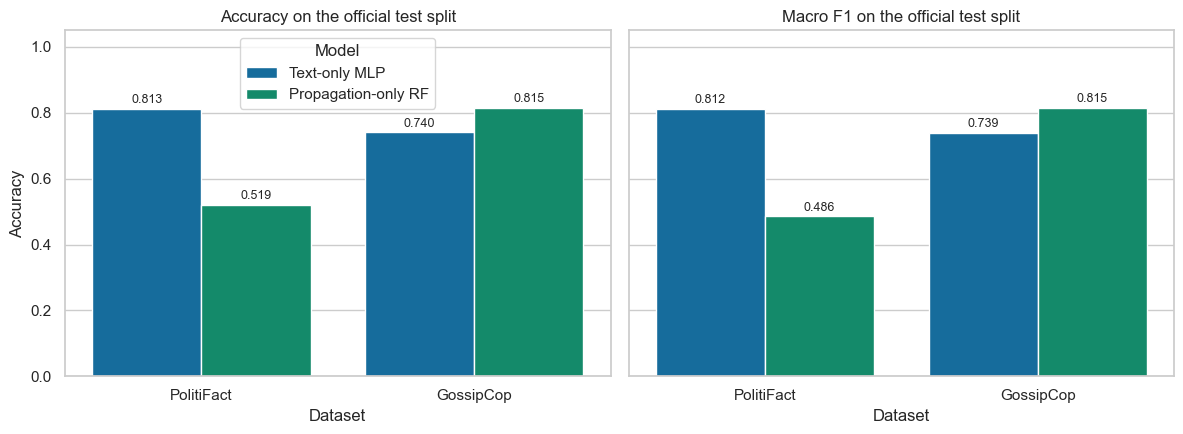

In [13]:
# Bar chart of accuracy and macro-F1 for both baselines.
long = COMPARISON.melt(id_vars=["Dataset", "Model"], value_vars=["Accuracy", "Macro F1"], var_name="metric", value_name="value")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
model_palette = {"Text-only MLP": "#0072B2", "Propagation-only RF": "#009E73"}
for ax, metric in zip(axes, ["Accuracy", "Macro F1"]):
    sub = long[long.metric == metric]
    sns.barplot(data=sub, x="Dataset", y="value", hue="Model", palette=model_palette, ax=ax)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.3f", fontsize=9, padding=2)
    ax.set_ylim(0, 1.05); ax.set_ylabel(metric); ax.set_title(f"{metric} on the official test split")
axes[1].get_legend().remove() if axes[1].get_legend() else None
plt.tight_layout()
save_figure(fig, BASE_FIG_DIR / "baseline_comparison_accuracy_f1.png")
plt.show()

## 8. Observations

In [14]:
# Write the main observations from the comparison table.
C = COMPARISON.set_index(["Dataset", "Model"])
lines = []
for name in DATASETS:
    t = DATASET_TITLES[name]
    have = [m for m in order_models if (t, m) in C.index]
    for m in have:
        r = C.loc[(t, m)]
        lines.append(f"[{t}] {m}: accuracy {r['Accuracy']:.3f} (95% CI {r['accuracy_ci95_low']:.3f}-{r['accuracy_ci95_high']:.3f}), "
                     f"macro-F1 {r['Macro F1']:.3f}, ROC-AUC {r['ROC-AUC']:.3f}.")
    if len(have) == 2:
        a, b = C.loc[(t, "Text-only MLP")], C.loc[(t, "Propagation-only RF")]
        better = "text-only MLP" if a["Macro F1"] > b["Macro F1"] else "propagation-only RF"
        lines.append(f"[{t}] the {better} has the higher macro-F1 (difference {abs(a['Macro F1'] - b['Macro F1']):.3f}); "
                     f"ROC-AUC difference {abs(a['ROC-AUC'] - b['ROC-AUC']):.3f}.")
for m in order_models:
    ts = [(t, C.loc[(t, m)]["Macro F1"]) for t in (DATASET_TITLES[n] for n in DATASETS) if (t, m) in C.index]
    if len(ts) == 2:
        lines.append(f"{m}: macro-F1 is {ts[0][1]:.3f} on {ts[0][0]} vs {ts[1][1]:.3f} on {ts[1][0]}.")
print("\n".join("- " + l for l in lines))

- [PolitiFact] Text-only MLP: accuracy 0.813 (95% CI 0.758-0.860), macro-F1 0.812, ROC-AUC 0.863.
- [PolitiFact] Propagation-only RF: accuracy 0.519 (95% CI 0.455-0.585), macro-F1 0.486, ROC-AUC 0.559.
- [PolitiFact] the text-only MLP has the higher macro-F1 (difference 0.326); ROC-AUC difference 0.304.
- [GossipCop] Text-only MLP: accuracy 0.740 (95% CI 0.726-0.754), macro-F1 0.739, ROC-AUC 0.811.
- [GossipCop] Propagation-only RF: accuracy 0.815 (95% CI 0.803-0.827), macro-F1 0.815, ROC-AUC 0.888.
- [GossipCop] the propagation-only RF has the higher macro-F1 (difference 0.076); ROC-AUC difference 0.078.
- Text-only MLP: macro-F1 is 0.812 on PolitiFact vs 0.739 on GossipCop.
- Propagation-only RF: macro-F1 is 0.486 on PolitiFact vs 0.815 on GossipCop.


Notes: PolitiFact has a small test split (one graph moves accuracy by a visible amount), and the two datasets differ in size and domain, so rankings can differ.